# Proyecto Integrador - Mineria de Datos
# Limpieza y preparacion de datos

**¿Se puede predecir que glosas medicas se van a recuperar?**

**Integrantes:** Sebastian Olarte, Gabriel Peñuela, Tomas Velasquez
**Curso:** Mineria de Datos

---

### Para que es este notebook

Este notebook es solo la parte de **limpieza y preparacion de datos** del proyecto. Trabajamos con el reporte real de glosas (objeciones) del hospital que nos paso el contador, y lo que buscamos es:

- Ver que tan buena o mala esta la calidad del dataset antes de tocar nada.
- Encontrar los problemas que de verdad tiene (no los que uno "cree" que deberia tener por default).
- Limpiar y transformar lo que haya que transformar, mostrando el antes y el despues de cada cosa que hicimos.
- Dejar un dataset listo para la siguiente etapa del proyecto.

El dataset tiene mas o menos 370.332 filas y 40 columnas, con informacion de enero a julio de 2026. Ojo que tiene datos personales (nombres de pacientes y medicos), asi que hay que tener cuidado con eso.

## 2. Importacion de librerias

Solo importamos lo que en verdad necesitamos para esta parte: pandas y numpy para manejar los datos, y matplotlib por si toca hacer algun grafico rapido de apoyo al diagnostico.

In [1]:
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

plt.rcParams['figure.figsize'] = (8, 4)

## 3. Carga del dataset

Ahora si, cargamos el dataset.

In [2]:
base = RAIZ / 'data/crudos/reporte dinamica enero a la fecha'
if base.with_suffix('.xlsx').exists():
    df = pd.read_excel(base.with_suffix('.xlsx'), sheet_name='DGDATATABLE', engine='calamine')
else:
    df = pd.read_csv(base.with_suffix('.csv'), sep=';', encoding='latin-1', low_memory=False)


# Copia intacta del dataset original, para poder comparar antes/después en cualquier momento
df_original = df.copy()

filas_iniciales = df.shape[0]
columnas_iniciales = df.shape[1]

print(f"Filas iniciales: {filas_iniciales:,}")
print(f"Columnas iniciales: {columnas_iniciales}")

Filas iniciales: 370,332
Columnas iniciales: 40


## 4. Diagnostico inicial

Antes de tocar cualquier dato, revisamos como llego el dataset tal cual, sin modificar nada todavia.

### 4.1 Dimensiones

In [3]:
print(f"Número de filas: {df.shape[0]:,}")
print(f"Número de columnas: {df.shape[1]}")

Número de filas: 370,332
Número de columnas: 40


### 4.2 Tipos de datos

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 370332 entries, 0 to 370331
Data columns (total 40 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Column1                          370332 non-null  object 
 1   Factura                          370332 non-null  object 
 2   Facturador                       370332 non-null  object 
 3   Fecha Factura                    370332 non-null  object 
 4   Ingreso                          370332 non-null  int64  
 5   Observacion Recepecion General   369096 non-null  object 
 6   Fecha de la Objecion             370332 non-null  object 
 7   Fecha Actualiza Saldo            370332 non-null  object 
 8   Codigo Conceptos Objecion        370332 non-null  object 
 9   Concepto de Objecion             370332 non-null  object 
 10  Observaciones por Item           260306 non-null  object 
 11  Hoja de Trabajo                  363320 non-null  float64
 12  Co

In [5]:
resumen_tipos = pd.DataFrame({
    'tipo_dato': df.dtypes.astype(str),
    'no_nulos': df.notna().sum(),
    'nulos': df.isna().sum(),
    'porcentaje_nulos_%': (df.isna().mean() * 100).round(2),
    'valores_unicos': df.nunique(dropna=True)
})
resumen_tipos.sort_values('porcentaje_nulos_%', ascending=False)

                                tipo_dato  no_nulos   nulos  porcentaje_nulos_%  valores_unicos
Numero Radicación Trámite         float64         0  370332               100.0               0
Codigo Servicio                    object    132706  237626                64.2            1428
Codigo Suministro                  object    230614  139718                37.7            1456
Observaciones por Item             object    260306  110026                29.7           19322
Observaciones Trámite              object    314425   55907                15.1            2017
OBSERVACION TRAMITE GENERAL        object    316942   53390                14.4             433
Etiqueta Objeción                 float64    317286   53046                14.3               1
Estado                             object    317286   53046                14.3               2
Concepto                           object    317286   53046                14.3              10
Valor Aceptado                     objec

### 4.3 Valores faltantes

In [6]:
faltantes = pd.DataFrame({
    'nulos': df.isna().sum(),
    'porcentaje_%': (df.isna().mean() * 100).round(2)
})
faltantes = faltantes[faltantes['nulos'] > 0].sort_values('porcentaje_%', ascending=False)
faltantes

                                  nulos  porcentaje_%
Numero Radicación Trámite        370332         100.0
Codigo Servicio                  237626          64.2
Codigo Suministro                139718          37.7
Observaciones por Item           110026          29.7
Observaciones Trámite             55907          15.1
OBSERVACION TRAMITE GENERAL       53390          14.4
Valor Aceptado                    53046          14.3
Estado                            53046          14.3
Concepto                          53046          14.3
Cod Concepto                      53046          14.3
Etiqueta Objeción                 53046          14.3
Especialidad                      13945           3.8
Valor Unitario Procedimiento       7012           1.9
Hoja de Trabajo                    7012           1.9
Servicio                           7012           1.9
Valor Entidad PROCEDIMIENTO        7012           1.9
Medico                             7012           1.9
Código Centro Costo Solicita

### 4.4 Duplicados

In [7]:
duplicados_exactos = df.duplicated().sum()
print(f"Duplicados exactos (fila 100% igual a otra): {duplicados_exactos:,}")
print(f"Porcentaje: {duplicados_exactos / len(df) * 100:.4f}%")

Duplicados exactos (fila 100% igual a otra): 0
Porcentaje: 0.0000%


**Sobre los "duplicados":** una misma `Factura` se puede repetir varias veces en el dataset, porque una factura puede tener varios servicios, varios items objetados o varios conceptos de objecion. Eso no es un duplicado, es simplemente como esta armado el dato (cada fila es un item objetado, no una factura completa). Antes de asumir cualquier cosa, miramos cuantas facturas se repiten y si esas repeticiones son items distintos o no.

In [8]:
facturas_repetidas = df['Factura'].value_counts()
print(f"Facturas distintas: {facturas_repetidas.shape[0]:,}")
print(f"Facturas que aparecen más de una vez: {(facturas_repetidas > 1).sum():,}")
print(f"Máximo de filas para una misma factura: {facturas_repetidas.max()}")
print()

Facturas distintas: 42,256
Facturas que aparecen más de una vez: 20,512
Máximo de filas para una misma factura: 1422



**Conclusion de esta parte:** las facturas que se repiten es porque tienen distintos items o servicios objetados dentro de la misma factura. Entonces no las vamos a tratar como duplicados.

### 4.5 Estadisticas descriptivas (variables numericas)

In [9]:
df.select_dtypes(include='number').drop(columns=['Ingreso', 'Hoja de Trabajo', 'Factura', 'Paciente', 'Medico', 'Facturador'], errors='ignore').describe().T

                              count  mean  std  min  25%  50%  75%  max
Numero Radicación Trámite       0.0   NaN  NaN  NaN  NaN  NaN  NaN  NaN
Etiqueta Objeción         317,286.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0

### 4.6 Variables categoricas

In [10]:
cols_categoricas_diag = ['Especialidad', 'Regimen', 'Entidad', 'Estado', 'Clase Objeción',
                          'Concepto de Objecion', 'Servicio', 'Etiqueta Objeción', 'Concepto']

for col in cols_categoricas_diag:
    print(f"--- {col} ---")
    print(f"Categorías distintas: {df[col].nunique(dropna=True)}")
    print(f"Valores nulos: {df[col].isna().sum()} ({df[col].isna().mean()*100:.2f}%)")
    print("Top 5 categorías más frecuentes:")
    print(df[col].value_counts(dropna=False).head(5))
    print()

--- Especialidad ---
Categorías distintas: 61
Valores nulos: 13945 (3.77%)
Top 5 categorías más frecuentes:
Especialidad
MEDICINA GENERAL    107433
ENFERMERIA           93801
MEDICINA INTERNA     27059
EST                  16445
NaN                  13945
Name: count, dtype: int64

--- Regimen ---
Categorías distintas: 12
Valores nulos: 0 (0.00%)
Top 5 categorías más frecuentes:
Regimen
CON    211814
SUB    126624
AAT     10051
ESS      6772
VIN      5411
Name: count, dtype: int64

--- Entidad ---
Categorías distintas: 144
Valores nulos: 0 (0.00%)
Top 5 categorías más frecuentes:
Entidad
ENTIDAD PROMOTORA DE SALUD SANITAS SAS DUITAMA CONTRIBUTIVO FI INDETERMINADO FF DCTO 2423- 15%            86426
ENTIDAD PROMOTORA DE SALUD FAMISANAR S A S DUITAMA CONTRIBUTIVO FI INDETERMINADO DCTO 2423 100%           82103
ENTIDAD PROMOTORA DE SALUD FAMISANAR EPS SUBSIDIADO DUITAMA SUBSIDIADO FI INDETERMINADO DCTO 2423 100%    60545
SALUD TOTAL DUITAMA CONTRIBUTIVO FI  01/08/2024 FF 31/1/08 2025 DCTO 

**Buscando inconsistencias de escritura** (mayusculas/minusculas, espacios de mas, categorias que en realidad son la misma cosa pero escrita distinto). Para esto comparamos cuantas categorias hay antes y despues de normalizar (quitando espacios y pasando todo a mayusculas).

In [11]:
print(f"{'Columna':25s} {'Únicas originales':>18s} {'Únicas normalizadas':>20s} {'Diferencia':>12s}")
for col in ['Especialidad', 'Regimen', 'Entidad', 'Estado', 'Servicio']:
    s = df[col].dropna().astype(str)
    n_original = s.nunique()
    n_normalizado = s.str.strip().str.upper().nunique()
    print(f"{col:25s} {n_original:18d} {n_normalizado:20d} {n_original - n_normalizado:12d}")

Columna                    Únicas originales  Únicas normalizadas   Diferencia
Especialidad                              61                   61            0
Regimen                                   12                   12            0
Entidad                                  144                  144            0
Estado                                     2                    2            0
Servicio                                2978                 2959           19


In [12]:
# Ejemplo concreto: categorías de 'Servicio' que colapsan al normalizar (misma cosa escrita distinto)
s = df['Servicio'].dropna().astype(str)
tmp = pd.DataFrame({'original': s, 'normalizado': s.str.strip().str.upper()})
grupos_con_variantes = tmp.groupby('normalizado')['original'].unique()
grupos_con_variantes = grupos_con_variantes[grupos_con_variantes.apply(len) > 1]

print(f"Categorías de 'Servicio' con variantes de escritura: {len(grupos_con_variantes)}")
for nombre_normalizado, variantes in list(grupos_con_variantes.items())[:5]:
    print(f" - {nombre_normalizado!r} <- {list(variantes)}")

Categorías de 'Servicio' con variantes de escritura: 19
 - 'ACETAMINOFEN JARABE 150 MG/5 ML FRASCO X 60 ML' <- ['Acetaminofen JARABE 150 MG/5 ML FRASCO X 60 ML', 'ACETAMINOFEN JARABE 150 MG/5 ML FRASCO X 60 ML']
 - 'ALPRAZOLAM TABLETA 0.25MG' <- ['ALPRAZOLAM TABLETA 0.25mg', 'ALPRAZOLAM TABLETA 0.25mg ']
 - 'APOSITO  PERIFERICO ADULTO  7 CM X 9 CM DE SEGURIDAD AVANZADO' <- ['APOSITO  PERIFERICO ADULTO  7 CM x 9 CM DE SEGURIDAD AVANZADO', 'APOSITO  PERIFERICO ADULTO  7 CM x 9 CM DE SEGURIDAD AVANZADO ']
 - 'CARBAMAZEPINA 200 MG TABLETA' <- ['CARBAMAZEPINA 200 mg TABLETA', 'CARBAMAZEPINA 200 mg TABLETA ']
 - 'CARVEDILOL 6.25MG TABLETA' <- ['CARVEDILOL 6.25mg TABLETA', 'CARVEDILOL 6.25mg TABLETA ']


In [13]:
# Espacios sobrantes en 'Entidad' (aunque no generan categorias nuevas, si ensucian el dato)
s = df['Entidad'].dropna().astype(str)
con_espacios = (s != s.str.strip()).sum()
print(f"Registros de 'Entidad' con espacios al inicio/final: {con_espacios:,} de {len(s):,}")

# Espacios sobrantes en el codigo de concepto de objecion
s2 = df['Codigo Conceptos Objecion'].dropna().astype(str)
con_espacios2 = (s2 != s2.str.strip()).sum()
print(f"Registros de 'Codigo Conceptos Objecion' con espacios al inicio/final: {con_espacios2:,} de {len(s2):,}")

Registros de 'Entidad' con espacios al inicio/final: 18,718 de 370,332
Registros de 'Codigo Conceptos Objecion' con espacios al inicio/final: 2,882 de 370,332


**Lo que encontramos:** hay 19 categorias de `Servicio` que en realidad estan duplicadas solo por diferencias de mayusculas o espacios, y tambien hay espacios de mas en varios registros de `Entidad` y de `Codigo Conceptos Objecion`.

### 4.7 Fechas

In [14]:
cols_fecha = ['Fecha Factura', 'Fecha de la Objecion', 'Fecha Actualiza Saldo', 'Fecha solicitud']

print("Tipos de dato actuales:")
print(df[cols_fecha].dtypes)

Tipos de dato actuales:
Fecha Factura            object
Fecha de la Objecion     object
Fecha Actualiza Saldo    object
Fecha solicitud          object
dtype: object


In [15]:
def fecha_reporte(serie):
    texto = serie.astype("string").str.strip()
    iso = texto.str.match(r"^\d{4}-", na=False)
    fechas = pd.to_datetime(texto.where(iso), format="ISO8601", errors="coerce")
    fechas.loc[~iso] = pd.to_datetime(texto[~iso], format="mixed", dayfirst=True, errors="coerce")
    return fechas

fmt = '%d/%m/%Y %H:%M'   # formato día/mes/año hora:minuto

fecha_factura_dt   = fecha_reporte(df['Fecha Factura'])
fecha_objecion_dt  = fecha_reporte(df['Fecha de la Objecion'])
fecha_saldo_dt     = fecha_reporte(df['Fecha Actualiza Saldo'])
fecha_solicitud_dt = fecha_reporte(df['Fecha solicitud'])

for nombre, serie_dt, original in [
    ('Fecha Factura', fecha_factura_dt, df['Fecha Factura']),
    ('Fecha de la Objecion', fecha_objecion_dt, df['Fecha de la Objecion']),
    ('Fecha Actualiza Saldo', fecha_saldo_dt, df['Fecha Actualiza Saldo']),
    ('Fecha solicitud', fecha_solicitud_dt, df['Fecha solicitud']),
]:
    print(nombre)
    print(f"  Minima: {serie_dt.min()}   Maxima: {serie_dt.max()}")
    print(f"  Nulos tras convertir: {serie_dt.isna().sum()} (nulos originales: {original.isna().sum()})")
    print()
# Esta columna si tiene el problema: viene mezclada con texto y con
# numeros (NaN se lee como float), entonces pandas no puede comparar
# directamente para sacar el min/max. La convertimos primero.
for c in ['Fecha solicitud', 'Fecha Actualiza Saldo']:
    df[c] = fecha_reporte(df[c])

Fecha Factura
  Minima: 2013-09-25 14:45:34   Maxima: 2026-07-08 16:53:19
  Nulos tras convertir: 0 (nulos originales: 0)

Fecha de la Objecion
  Minima: 2026-01-01 00:00:00   Maxima: 2026-07-17 09:51:00
  Nulos tras convertir: 0 (nulos originales: 0)

Fecha Actualiza Saldo
  Minima: 2018-02-28 18:34:00   Maxima: 2026-07-17 16:53:00
  Nulos tras convertir: 0 (nulos originales: 0)

Fecha solicitud
  Minima: 2013-09-21 03:05:00   Maxima: 2026-07-05 16:46:00
  Nulos tras convertir: 7012 (nulos originales: 7012)



**Lo que vemos:** `Fecha de la Objecion` si queda dentro del periodo que esperabamos (enero a julio de 2026), tal como se mostro en la presentacion del proyecto. En cambio `Fecha Factura` tiene un rango mucho mas amplio, desde 2013, pero eso tiene sentido: una factura vieja puede seguir tramitandose o siendo objetada años despues. No es un dato raro ni un error, es simplemente como funciona la cartera de un hospital.

Ahora si revisamos algo que seria un problema real: que la fecha de la objecion quede antes que la fecha de la factura, porque eso si seria imposible.

In [16]:
inconsistentes_fecha = (df['Fecha de la Objecion'] < fecha_factura_dt).sum()
print(f"Filas donde la objeción es anterior a la factura (imposible): {inconsistentes_fecha}")

Filas donde la objeción es anterior a la factura (imposible): 26991


### 4.8 Variables monetarias

In [17]:
cols_monetarias = [
    'Valor Unitario Procedimiento', 'Valor TotServicio PROCEDIMIENTO', 'Valor Entidad PROCEDIMIENTO',
    'Valor Paciente PROCEDIMIENTO', 'Valor Objeción', 'Valor Aceptado', 'Abonado', 'Saldo'
]

# Antes de calcular nada revisamos los tipos: si alguna de estas columnas
# quedo como 'object' (texto) en vez de numerica, .min()/.max() truena por
# la misma razon que las fechas (mezcla de numeros y texto/NaN).
print("Tipos de dato antes de convertir:")
print(df[cols_monetarias].dtypes)
print()

def convertir_a_numero(serie):
    # Si ya es numerica, no tocamos nada
    if pd.api.types.is_numeric_dtype(serie):
        return serie
    # Si quedo como texto, probablemente algunos valores vienen en formato
    # numerico en español (punto como separador de miles, coma como decimal),
    # por eso pandas no la pudo leer como numero directamente. Solo aplicamos
    # el reemplazo en los valores que sí tienen coma; el resto se deja igual.
    s = serie.astype(str).str.strip()
    s = s.replace({'nan': None, 'None': None, '': None})
    tiene_coma = s.str.contains(',', na=False)
    s.loc[tiene_coma] = s.loc[tiene_coma].str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')

for col in cols_monetarias:
    if not pd.api.types.is_numeric_dtype(df[col]):
        antes = df[col].copy()
        df[col] = convertir_a_numero(df[col])
        no_convertidos = antes.notna().sum() - df[col].notna().sum()
        if no_convertidos:
            raise ValueError(f"{col}: {no_convertidos} importes no reconocidos. Revisa el archivo de origen.")
        print(f"  '{col}' se convirtio de texto a numero. Valores que no se pudieron convertir (quedaron NaN): {no_convertidos}")

print()
print("Tipos de dato despues de convertir:")
print(df[cols_monetarias].dtypes)
print()

resumen_monetario = pd.DataFrame({
    'min': df[cols_monetarias].min(),
    'max': df[cols_monetarias].max(),
    'media': df[cols_monetarias].mean(),
    'mediana': df[cols_monetarias].median(),
    'desv_estandar': df[cols_monetarias].std(),
    'ceros': (df[cols_monetarias] == 0).sum(),
    'negativos': (df[cols_monetarias] < 0).sum(),
    'nulos': df[cols_monetarias].isna().sum(),
})
resumen_monetario

Tipos de dato antes de convertir:
Valor Unitario Procedimiento       object
Valor TotServicio PROCEDIMIENTO    object
Valor Entidad PROCEDIMIENTO        object
Valor Paciente PROCEDIMIENTO       object
Valor Objeción                     object
Valor Aceptado                     object
Abonado                            object
Saldo                              object
dtype: object

  'Valor Unitario Procedimiento' se convirtio de texto a numero. Valores que no se pudieron convertir (quedaron NaN): 0
  'Valor TotServicio PROCEDIMIENTO' se convirtio de texto a numero. Valores que no se pudieron convertir (quedaron NaN): 0
  'Valor Entidad PROCEDIMIENTO' se convirtio de texto a numero. Valores que no se pudieron convertir (quedaron NaN): 0
  'Valor Paciente PROCEDIMIENTO' se convirtio de texto a numero. Valores que no se pudieron convertir (quedaron NaN): 0
  'Valor Objeción' se convirtio de texto a numero. Valores que no se pudieron convertir (quedaron NaN): 0
  'Valor Aceptado' se convi

                                         min           max        media     mediana  desv_estandar   ceros  negativos  nulos
Valor Unitario Procedimiento             1.0  16,293,480.0    109,358.2    11,242.0      433,668.8       0          0   7012
Valor TotServicio PROCEDIMIENTO          0.0  37,567,188.0    115,649.8    13,800.0      535,714.4    4188          0   7012
Valor Entidad PROCEDIMIENTO              0.0  16,293,480.0     92,144.0    10,751.0      386,948.0    4188          0   7012
Valor Paciente PROCEDIMIENTO             0.0   2,271,490.0      1,265.7         0.0       17,825.3  326133          0   7012
Valor Objeción                           1.0 181,138,368.0    144,182.0     9,058.0    1,296,470.2       0          0      0
Valor Aceptado                           0.0 181,138,368.0     31,308.9         0.0      914,535.1  309521          0  53046
Abonado                         -9,208,920.0 206,190,876.0  5,948,984.2   372,015.0   17,057,355.9  113523         74      0


**Cosas que encontramos (todavia no corregimos nada, solo estamos anotando):**

- `Valor Objeción` no tiene ceros, negativos ni nulos, lo cual tiene sentido porque toda objecion deberia tener un valor.
- `Valor Aceptado` tiene 53.046 nulos y resulta que son exactamente las mismas filas que estan en estado pendiente (lo vemos en la seccion 14). Entonces no es un dato que falte por error, es que ese resultado todavia no existe porque el tramite no se ha resuelto.
- `Abonado` tiene 74 valores negativos. Antes de pensar que es un error hay que ver que significan esos negativos (lo hacemos en la seccion 15).
- Los valores de `Valor Unitario Procedimiento` hasta `Valor Paciente PROCEDIMIENTO` van desde 0/1 hasta mas de 16 millones, lo cual tiene sentido porque un hospital maneja desde un insumo barato hasta una cirugia complicada.

## 5. Problemas de calidad identificados

Con base en el diagnostico de la seccion 4, esta es la lista de los problemas que de verdad tiene el dataset (no ponemos cosas que uno esperaria encontrar pero que no aparecieron, como fechas imposibles o mayusculas mal puestas en `Especialidad`/`Regimen`/`Estado`):

| # | Problema | Variable(s) afectada(s) | Evidencia | Accion propuesta | Justificacion |
|---|---|---|---|---|---|
| 1 | Columnas constantes/vacias, sin informacion | `Column1`, `Column2`, `Numero Radicación Trámite` | Un unico valor en todo el dataset o 100% nulas | Eliminar | No aportan nada al analisis ni al modelo |
| 2 | Informacion personal identificable | `Paciente`, `Medico`, `Facturador` | 26.449 / 1.082 / 75 valores unicos, nombres reales | Eliminar | Privacidad; no son relevantes para el objetivo predictivo |
| 3 | Tipo de dato incorrecto en fechas | `Fecha Factura` | Cargada como `object` en vez de `datetime` | Convertir a `datetime` | Necesario para cualquier calculo temporal posterior |
| 4 | Inconsistencias de texto (espacios sobrantes) | `Entidad`, `Codigo Conceptos Objecion` | 18.718 y 2.882 registros con espacios al inicio/final respectivamente | Quitar espacios (`strip`) | Evita que el mismo valor se trate como distinto en agrupaciones |
| 5 | Categorias duplicadas por diferencias de escritura | `Servicio` | 19 grupos de categorias que colapsan al normalizar mayusculas/espacios | Normalizar a mayusculas y espacios simples | Evita fragmentar la misma categoria en varias |
| 6 | Artefactos de exportacion en texto libre | `Observacion Recepecion General`, `Observaciones por Item`, `OBSERVACION TRAMITE GENERAL`, `Observaciones Trámite` | 184.237 filas con el artefacto `_x000D_` (salto de linea mal codificado) | Limpiar el artefacto | Deja el texto legible y evita ruido en cualquier procesamiento de texto |
| 7 | Valores faltantes estructurales ligados al item de servicio | `Servicio`, `Codigo Servicio`, `Especialidad`, `Centro de Costo`, valores del procedimiento | ~7.012 filas corresponden a objeciones globales a la factura, sin item especifico | Marcar con categoria `"Sin informacion"` en vez de imputar o eliminar | El nulo tiene un significado real (objecion a nivel de factura), no es un dato perdido por error |
| 8 | Registros sin resultado definitivo | `Estado`, `Valor Aceptado`, `Etiqueta Objeción`, `Concepto` | 53.046 filas "Pendiente" (Estado nulo) + 684 "Anulado" | Excluir del conjunto de entrenamiento (conservar aparte) | No tienen aun un desenlace conocido; no se pueden usar para clasificacion supervisada |
| 9 | Columna sin variabilidad real una vez confirmado el tramite | `Etiqueta Objeción` | Toma un unico valor (0.0) en el 100% de los casos confirmados | Documentar como poco informativa; no se usara como predictora | No permite distinguir clases, aporta cero informacion al modelo |
| 10 | Ausencia de variable objetivo explicita | — | El reporte no trae una columna de resultado (recuperada/no recuperada) | Derivarla a partir de `Valor Aceptado` | Es la definicion operativa acordada con el hospital para este proyecto |
| 11 | Desbalance fuerte de clases (una vez derivada la variable objetivo) | `Recuperada` (derivada) | ~97,6% recuperada vs ~2,3% no recuperada | Documentar; no corregir en esta etapa | El balanceo de clases es una decision de modelado, no de limpieza |
| 12 | Posible inconsistencia de granularidad entre variables | `Abonado`, `Saldo` vs. el resto de columnas monetarias | `Abonado` y `Saldo` se repiten identicos para todos los items de una misma factura (son valores a nivel de factura, no de item) | Documentar; no usar como predictoras a nivel de item sin transformarlas | Usarlas tal cual introduciria una variable que en realidad describe la factura completa, no el item individual |
| 13 | Valores negativos en una variable monetaria | `Abonado` | 74 registros con valores negativos | Investigar (seccion 15); no eliminar de forma automatica | Podria representar un ajuste contable valido (reversion), no necesariamente un error |

**Cosas que buscamos y NO encontramos** (las dejamos anotadas porque la actividad lo pide): casi no hay duplicados exactos de fila (solo un puñado, ver seccion 4.4); no hay problemas de mayusculas en `Especialidad`, `Regimen` ni `Estado`; no hay fechas de objecion fuera del periodo enero-julio 2026; y no hay casos donde `Valor Aceptado` sea mayor que `Valor Objeción`.

## 6. Eliminacion de columnas sin utilidad

En la seccion de arriba encontramos tres columnas que no sirven para nada: `Column1`, `Column2` y `Numero Radicación Trámite`. En una version anterior de este notebook las habiamos puesto en la tabla de problemas pero se nos quedo sin hacer el paso de eliminarlas en el codigo (quedo solo en el papel). Aqui lo arreglamos: primero comprobamos con codigo por que no sirven, y ahi si las quitamos de verdad.

In [18]:
cols_sin_utilidad = ['Column1', 'Column2', 'Numero Radicación Trámite']

print("Antes de eliminar — columnas totales:", df.shape[1])
for c in cols_sin_utilidad:
    print(f"  {c}: {df[c].nunique(dropna=True)} valor(es) único(s), "
          f"{df[c].isna().sum():,} nulos de {len(df):,} filas ({df[c].isna().mean()*100:.1f}%)")

df = df.drop(columns=cols_sin_utilidad)

print()
print("Columnas eliminadas por falta de utilidad:", cols_sin_utilidad)
print("Motivo: son constantes (un único valor en todo el dataset) o están 100% vacías, "
      "no aportan ninguna capacidad de discriminación para un modelo")
print("Columnas restantes:", df.shape[1])

Antes de eliminar — columnas totales: 40
  Column1: 1 valor(es) único(s), 0 nulos de 370,332 filas (0.0%)
  Column2: 1 valor(es) único(s), 0 nulos de 370,332 filas (0.0%)
  Numero Radicación Trámite: 0 valor(es) único(s), 370,332 nulos de 370,332 filas (100.0%)

Columnas eliminadas por falta de utilidad: ['Column1', 'Column2', 'Numero Radicación Trámite']
Motivo: son constantes (un único valor en todo el dataset) o están 100% vacías, no aportan ninguna capacidad de discriminación para un modelo
Columnas restantes: 37


**Comprobamos que:** `Column1` solo tiene el valor "RECEPCION" y `Column2` solo tiene "TRAMITE" en las 370.332 filas, seguramente son etiquetas fijas que vienen del reporte del sistema de facturacion y no datos reales. `Numero Radicación Trámite` esta 100% vacia. Ninguna de las tres le sirve a un modelo predictivo, asi que las podemos eliminar sin problema.

## 7. Eliminacion de informacion personal

El dataset trae tres columnas con informacion personal: `Paciente`, `Medico` y `Facturador`. Ninguna de las tres nos sirve para lo que queremos predecir, porque si una glosa se recupera o no depende mas bien del motivo de la objecion, la especialidad, la entidad y los valores en juego, no de quien es la persona. Las eliminamos por dos razones: privacidad de los pacientes y del personal medico, y porque no aportan nada al modelo.

In [19]:
columnas_personales = ['Paciente', 'Medico', 'Facturador']

print("Antes de eliminar — columnas totales:", df.shape[1])
for c in columnas_personales:
    print(f"  {c}: {df[c].nunique()} valores únicos (información personal identificable)")

df = df.drop(columns=columnas_personales)

print()
print("Columnas eliminadas por contener información personal:", columnas_personales)
print("Motivo: privacidad de pacientes/médicos y sin valor predictivo para el objetivo del proyecto")
print("Columnas restantes:", df.shape[1])

Antes de eliminar — columnas totales: 37
  Paciente: 26449 valores únicos (información personal identificable)
  Medico: 1082 valores únicos (información personal identificable)
  Facturador: 75 valores únicos (información personal identificable)

Columnas eliminadas por contener información personal: ['Paciente', 'Medico', 'Facturador']
Motivo: privacidad de pacientes/médicos y sin valor predictivo para el objetivo del proyecto
Columnas restantes: 34


## 8. Limpieza de nombres de columnas

Revisamos si los nombres de las columnas tienen espacios de mas, doble espacio o algun otro problema de formato, antes de decidir si toca normalizarlos.

In [20]:
nombres_originales = list(df.columns)
nombres_con_problema = [c for c in nombres_originales if c != c.strip() or '  ' in c]

print(f"Columnas con espacios sobrantes o dobles espacios: {len(nombres_con_problema)}")
print(nombres_con_problema)

Columnas con espacios sobrantes o dobles espacios: 0
[]


**Resultado:** ningun nombre de columna tiene espacios de mas ni doble espacio, los 34 nombres que hay estan bien y se pueden usar tal cual. Entonces en esta seccion no cambiamos nada, no vamos a renombrar columnas solo porque si.

## 9. Limpieza de texto

Con los problemas de texto que ya confirmamos en la seccion 4.6, limpiamos solo las columnas que en verdad lo necesitan (no todas):

- Columnas de texto libre (las observaciones): les quitamos el `_x000D_` y los saltos de linea, y dejamos los espacios multiples en uno solo.
- `Entidad` y `Codigo Conceptos Objecion`: les quitamos los espacios de mas al principio o al final.
- `Servicio`: la pasamos a mayusculas y espacios simples, para juntar las 19 categorias que estaban duplicadas solo por como estaban escritas.
- Las otras columnas categoricas que vamos a usar como predictoras (`Especialidad`, `Regimen`, `Concepto de Objecion`, `Centro de Costo`): tambien las pasamos a mayusculas por si acaso, aunque el diagnostico no encontro duplicados ahi, para que no den problema si en el futuro llegan datos con mayusculas distintas.

Las columnas que no son texto (identificadores numericos, fechas, valores de dinero) las dejamos con su tipo original, no las tocamos.

In [21]:
cols_observaciones = [
    'Observacion Recepecion General', 'Observaciones por Item',
    'OBSERVACION TRAMITE GENERAL', 'Observaciones Trámite'
]

for c in cols_observaciones:
    df[c] = (
        df[c].astype('string')
        .str.replace('_x000D_', ' ', regex=False)
        .str.replace('\r\n', ' ', regex=False)
        .str.replace('\n', ' ', regex=False)
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

In [22]:
restantes_x000d = sum(df[c].astype('string').str.contains('_x000D_', na=False).sum() for c in cols_observaciones)
print(f"Ocurrencias restantes de '_x000D_' en columnas de observaciones: {restantes_x000d}")

Ocurrencias restantes de '_x000D_' en columnas de observaciones: 0


In [23]:
df['Entidad'] = df['Entidad'].astype('string').str.strip()
df['Codigo Conceptos Objecion'] = df['Codigo Conceptos Objecion'].astype('string').str.strip()

print("Entidad — espacios sobrantes después:", (df['Entidad'].dropna() != df['Entidad'].dropna().str.strip()).sum())
print("Codigo Conceptos Objecion — espacios sobrantes después:",
      (df['Codigo Conceptos Objecion'].dropna() != df['Codigo Conceptos Objecion'].dropna().str.strip()).sum())

Entidad — espacios sobrantes después: 0
Codigo Conceptos Objecion — espacios sobrantes después: 0


In [24]:
print("Servicio — categorías únicas antes de normalizar:", df['Servicio'].nunique())

df['Servicio'] = df['Servicio'].astype('string').str.strip().str.upper().str.replace(r'\s+', ' ', regex=True)

print("Servicio — categorías únicas después de normalizar:", df['Servicio'].nunique())

Servicio — categorías únicas antes de normalizar: 2978
Servicio — categorías únicas después de normalizar: 2952


In [25]:
cols_categoricas_normalizar = ['Especialidad', 'Regimen', 'Concepto de Objecion', 'Centro de Costo']
for c in cols_categoricas_normalizar:
    df[c] = df[c].astype('string').str.strip().str.upper()

## 10. Tratamiento de valores faltantes

No eliminamos filas de una porque si. Para cada grupo de columnas con nulos, miramos que significa realmente ese nulo y lo metimos en una de estas 4 categorias:

1. **Se puede eliminar la columna** (no sirve para nada, o ya se habia eliminado por otro motivo).
2. **Se deja el nulo tal cual** (tiene sentido que este vacio porque ese resultado todavia no existe).
3. **Se puede imputar** (en este dataset no encontramos ninguna columna donde imputar con media o mediana tenga sentido, ver la justificacion de abajo).
4. **Se cambia por una categoria explicita `"Sin informacion"`** (el nulo si tiene un significado de negocio: es una objecion que no tiene un item puntual).

| Columna(s) | % nulos | Categoria de tratamiento | Justificacion |
|---|---|---|---|
| `Servicio`, `Codigo Servicio`, `Centro de Costo`, `Especialidad`, `Codigo Servicio`, valores del procedimiento (`Valor Unitario/TotServicio/Entidad/Paciente PROCEDIMIENTO`) | ~1,9% (7.012 filas) | (4) Categoria explicita para las categoricas; se conserva el nulo numerico | Corresponden a objeciones hechas sobre la factura completa, no sobre un item/servicio puntual, el nulo es la respuesta correcta, no un dato faltante por error. Imputar un valor monetario inventado distorsionaria el analisis. |
| `Estado`, `Valor Aceptado`, `Etiqueta Objeción`, `Concepto`, `Cod Concepto`, `OBSERVACION TRAMITE GENERAL` | ~14,3% (53.046 filas) | (2) Se conserva el nulo, y estas filas se excluyen del conjunto de entrenamiento (seccion 14) | El tramite todavia esta pendiente, no existe un resultado que registrar. Imputar aqui seria inventar el resultado que justamente se quiere predecir. |
| `Observaciones por Item`, `Observaciones Trámite` | 29,7% / 15,1% | (2) Se conserva el nulo | Son campos de texto libre opcionales, su ausencia no afecta variables numericas ni la variable objetivo. |
| `Codigo Servicio` (adicional a lo anterior, hay mas nulos que en `Servicio`) | 64,2% | (4) Categoria explicita `"Sin codigo"` | Hay mas registros sin codigo de servicio que sin nombre de servicio, se documenta como una inconsistencia menor entre ambas columnas, y se trata igual que un nulo estructural. |
| `Hoja de Trabajo` | 1,9% | (2) Se conserva el nulo | Es un campo administrativo interno del sistema, no se usara como variable predictora. |

No usamos imputacion de media ni mediana en ninguna variable numerica, porque los nulos que encontramos (`Valor Unitario/TotServicio/Entidad/Paciente PROCEDIMIENTO`, `Valor Aceptado`) significan "no aplica" o "el resultado todavia no existe", no "se perdio el dato por accidente". Poner un promedio ahi seria meterle al dataset una informacion que no es real.

In [26]:
cols_estructurales_categoricas = ['Especialidad', 'Servicio', 'Centro de Costo']
for c in cols_estructurales_categoricas:
    faltan_antes = df[c].isna().sum()
    df[c] = df[c].fillna('SIN INFORMACION')
    print(f"{c}: {faltan_antes} nulos -> reemplazados por 'SIN INFORMACION'")

faltan_antes = df['Codigo Servicio'].isna().sum()
df['Codigo Servicio'] = df['Codigo Servicio'].fillna('SIN CODIGO')
print(f"Codigo Servicio: {faltan_antes} nulos -> reemplazados por 'SIN CODIGO'")

Especialidad: 13945 nulos -> reemplazados por 'SIN INFORMACION'
Servicio: 7012 nulos -> reemplazados por 'SIN INFORMACION'
Centro de Costo: 7012 nulos -> reemplazados por 'SIN INFORMACION'
Codigo Servicio: 237626 nulos -> reemplazados por 'SIN CODIGO'


In [27]:
# Verificación: las columnas numéricas ligadas al ítem (Valor Unitario, TotServicio, Entidad, Paciente PROCEDIMIENTO)
# CONSERVAN su nulo intencionalmente (no se imputan)
cols_valor_item = ['Valor Unitario Procedimiento', 'Valor TotServicio PROCEDIMIENTO',
                    'Valor Entidad PROCEDIMIENTO', 'Valor Paciente PROCEDIMIENTO']
print("Nulos conservados intencionalmente (sin imputar):")
print(df[cols_valor_item].isna().sum())

Nulos conservados intencionalmente (sin imputar):
Valor Unitario Procedimiento       7012
Valor TotServicio PROCEDIMIENTO    7012
Valor Entidad PROCEDIMIENTO        7012
Valor Paciente PROCEDIMIENTO       7012
dtype: int64


## 11. Duplicados

En la seccion 4.4, con el dataset original completo (todavia con `Paciente`, `Medico` y `Facturador`), no encontramos duplicados exactos. Ahora lo volvemos a revisar, pero ya despues de quitar las columnas que no servian, quitar la info personal, y limpiar/normalizar texto y nulos. Hacemos esto porque cualquiera de esos cambios puede hacer que dos filas que antes se veian "distintas" por un detalle de formato terminen quedando idénticas.

**Importante, esto NO lo vamos a hacer:** no vamos a asumir que una factura que se repite es un duplicado (eso ya lo descartamos en la seccion 4.4, una factura puede tener varios items perfectamente). Tampoco vamos a borrar filas automaticamente solo porque parezcan duplicadas, primero analizamos y solo eliminamos si hay evidencia clara de que es un error de digitacion o de exportacion.

In [28]:
dup_mask = df.duplicated(keep=False)
print(f"Filas que pertenecen a algún grupo de duplicados exactos: {dup_mask.sum()}")

grupos = df[dup_mask].groupby(list(df.columns), dropna=False).ngroups
print(f"Número de grupos de filas idénticas: {grupos}")

print("Facturas diferentes afectadas:", df.loc[dup_mask, "Factura"].nunique())

Filas que pertenecen a algún grupo de duplicados exactos: 18
Número de grupos de filas idénticas: 9
Facturas diferentes afectadas: 1


**¿Por que aparecen ahora y no en la seccion 4.4?** Comprobamos que no es solo por haber quitado `Paciente`, `Medico` y `Facturador`, porque si solo quitamos esas tres columnas, los duplicados exactos siguen siendo 0. Lo que en realidad genera estos duplicados es la limpieza del `_x000D_` y de los saltos de linea en las observaciones (seccion 9). Habia pares de filas que eran idénticas en todo lo demas pero se diferenciaban en un detallito de formato dentro de un texto libre, por ejemplo un espacio extra o un salto de linea de mas. Al limpiar ese ruido, esas filas quedan exactamente iguales.

**Lo que encontramos:** son 9 pares de filas (18 filas en total) y todas son de una sola factura. Dentro de esa factura hay varios items (paracetamol, suero, jeringas, cateter, etc.) que se repiten con el mismo valor de objecion y el mismo motivo. Algo importante: todos estos items tienen `Codigo Servicio` nulo, o sea que no traen un codigo que identifique el insumo de forma unica dentro de la factura. Eso quiere decir que no tenemos manera de comprobar, con la info que tenemos, si por ejemplo "2 jeringas" son dos filas que en realidad describen el mismo evento repetido por error, o si de verdad se usaron 2 jeringas distintas durante la atencion (que seria lo normal en una hospitalizacion).

**Decision:** como no hay evidencia suficiente de que sea un error administrativo o de exportacion, no eliminamos estas 9 filas. Se dejan documentadas y se conservan igual que el resto del dataset. Esto va en linea con lo que dijimos en la seccion 4.4: una factura puede tener varios items y no vamos a decidir por nuestra cuenta que algo es un error sin tener evidencia real.

In [29]:
# Verificación: el dataset NO pierde filas por este análisis (decisión: conservar)
print(f"Filas en df antes de esta sección y después de esta sección: {df.shape[0]:,} (sin cambios)")

Filas en df antes de esta sección y después de esta sección: 370,332 (sin cambios)


## 12. Fechas

Convertimos `Fecha Factura` a `datetime` (ya vimos en la seccion 4.7 que esto no genera nulos nuevos ni problemas). Tambien sacamos variables derivadas de `Fecha de la Objecion` (año, mes, dia de la semana), porque estas si nos sirven para el analisis: podemos ver como evolucionan las objeciones mes a mes (como se mostro en la presentacion) y ver si hay algun patron por dia de la semana. De las otras fechas no sacamos nada derivado porque no le aportan al objetivo del proyecto en esta parte.

In [30]:
nulos_antes_conversion = df['Fecha Factura'].isna().sum()
df['Fecha Factura'] = fecha_reporte(df['Fecha Factura'])
nulos_despues_conversion = df['Fecha Factura'].isna().sum()

print(f"Nulos en Fecha Factura antes de convertir: {nulos_antes_conversion}")
print(f"Nulos en Fecha Factura despues de convertir: {nulos_despues_conversion}")
print(f"Tipo de dato final: {df['Fecha Factura'].dtype}")

# 'Fecha de la Objecion' tambien la necesitamos como datetime para poder
# sacarle año/mes/dia de la semana en la siguiente celda (el .dt solo
# funciona sobre columnas ya convertidas, si no queda como object truena).
nulos_antes_objecion = df['Fecha de la Objecion'].isna().sum()
df['Fecha de la Objecion'] = fecha_reporte(df['Fecha de la Objecion'])
nulos_despues_objecion = df['Fecha de la Objecion'].isna().sum()

print()
print(f"Nulos en Fecha de la Objecion antes de convertir: {nulos_antes_objecion}")
print(f"Nulos en Fecha de la Objecion despues de convertir: {nulos_despues_objecion}")
print(f"Tipo de dato final: {df['Fecha de la Objecion'].dtype}")

Nulos en Fecha Factura antes de convertir: 0
Nulos en Fecha Factura despues de convertir: 0
Tipo de dato final: datetime64[ns]

Nulos en Fecha de la Objecion antes de convertir: 0
Nulos en Fecha de la Objecion despues de convertir: 0
Tipo de dato final: datetime64[ns]


In [31]:
df['Anio Objecion'] = df['Fecha de la Objecion'].dt.year
df['Mes Objecion'] = df['Fecha de la Objecion'].dt.month
df['Dia Semana Objecion'] = df['Fecha de la Objecion'].dt.day_name()

## 13. Valores atipicos

Miramos los valores atipicos de `Valor Objeción` (que es la variable de dinero mas importante para el problema) usando el metodo de IQR y percentiles. En datos financieros de un hospital, un valor bien alto (por ejemplo una cirugia complicada) es completamente normal, asi que no lo vamos a eliminar solo porque sea grande.

In [32]:
q1 = df['Valor Objeción'].quantile(0.25)
q3 = df['Valor Objeción'].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = df[(df['Valor Objeción'] < limite_inferior) | (df['Valor Objeción'] > limite_superior)]

print(f"Q1: {q1:,.0f}   Q3: {q3:,.0f}   IQR: {iqr:,.0f}")
print(f"Límite inferior: {limite_inferior:,.0f}   Límite superior: {limite_superior:,.0f}")
print(f"Registros marcados como atípicos por IQR: {len(atipicos):,} ({len(atipicos)/len(df)*100:.1f}% del total)")

Q1: 2,215   Q3: 36,700   IQR: 34,485
Límite inferior: -49,512   Límite superior: 88,428
Registros marcados como atípicos por IQR: 50,421 (13.6% del total)


In [33]:
df['Valor Objeción'].describe(percentiles=[.01, .25, .5, .75, .90, .95, .99])

count       370,332.0
mean        144,182.0
std       1,296,470.2
min               1.0
1%              101.0
25%           2,215.0
50%           9,058.0
75%          36,700.0
90%         156,933.0
95%         408,953.6
99%       2,654,248.4
max     181,138,368.0

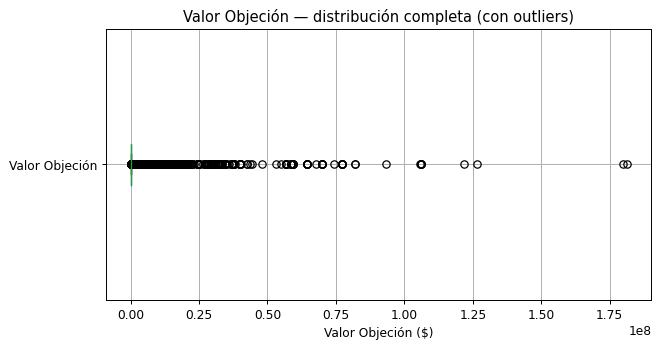

In [34]:
df.boxplot(column='Valor Objeción', vert=False)
plt.title('Valor Objeción — distribución completa (con outliers)')
plt.xlabel('Valor Objeción ($)')
plt.show()

**Decision:** aunque el metodo IQR marca varios registros como "atipicos", cuando revisamos esos valores mas altos vemos que son procedimientos complicados (cirugias, estancias en UCI), no errores de digitacion (no hay valores negativos raros ni con digitos de mas que se noten). Entonces no eliminamos ningun registro solo por ser atipico, son datos extremos pero reales, y si los quitaramos le estariamos quitando al hospital justo los casos con mas plata en juego, que son los mas importantes para el problema de negocio.

## 14. Variable objetivo (`Recuperada`)

Antes de armar la variable, revisamos como esta `Valor Aceptado`: cuantos nulos tiene, si hay negativos y si hay algo raro.

In [35]:
print("Valores nulos en Valor Aceptado:", df['Valor Aceptado'].isna().sum())
print("Valores negativos en Valor Aceptado:", (df['Valor Aceptado'] < 0).sum())
print("Valores donde Valor Aceptado > Valor Objeción (inconsistente):",
      (df['Valor Aceptado'] > df['Valor Objeción']).sum())

Valores nulos en Valor Aceptado: 53046
Valores negativos en Valor Aceptado: 0
Valores donde Valor Aceptado > Valor Objeción (inconsistente): 0


No hay valores negativos ni casos donde el valor aceptado sea mayor que el valor objetado. Los unicos nulos son los 53.046 casos pendientes, que vamos a excluir del entrenamiento en la siguiente seccion. La variable objetivo la construimos solo donde `Valor Aceptado` si tiene un valor conocido.

In [36]:
if df["Valor Aceptado"].lt(0).any():
    raise ValueError("Revisa los valores aceptados negativos antes de asignar etiquetas.")
df['Recuperada'] = pd.Series(
    np.where(df['Valor Aceptado'] == 0, 'Recuperada', 'No recuperada'),
    index=df.index, dtype='object'
)
df.loc[df['Valor Aceptado'].isna(), 'Recuperada'] = np.nan

df['Recuperada'].value_counts(dropna=False)

Recuperada
Recuperada       309521
NaN               53046
No recuperada      7765

Recuperada: 309,521 (97.6%)
No recuperada: 7,765 (2.4%)


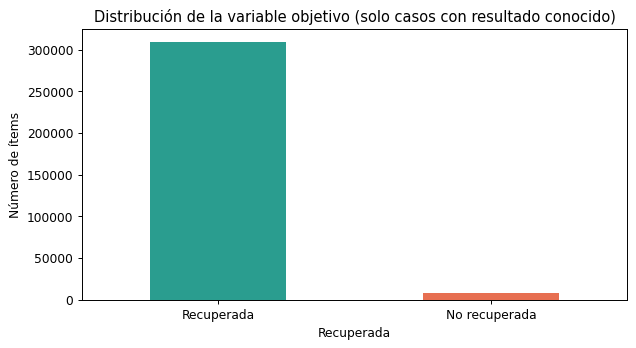

In [37]:
dist = df['Recuperada'].value_counts(dropna=True)
dist_pct = df['Recuperada'].value_counts(normalize=True, dropna=True) * 100

for clase in dist.index:
    print(f"{clase}: {dist[clase]:,} ({dist_pct[clase]:.1f}%)")

dist.plot(kind='bar', color=['#2a9d8f', '#e76f51'])
plt.title('Distribución de la variable objetivo (solo casos con resultado conocido)')
plt.ylabel('Número de ítems')
plt.xticks(rotation=0)
plt.show()

**Nota:** la clase esta bastante desbalanceada (mas o menos 97,6% contra 2,3%). Dejamos esto anotado para la etapa de modelado (ahi se veria si toca balancear, usar metricas distintas a *accuracy*, etc.), pero no lo corregimos en esta etapa porque corregirlo cambiaria el dataset real y eso le corresponde al modelado, no a la limpieza.

## 15. Registros pendientes y anulados

Revisamos la columna `Estado` para separar los registros que ya tienen un resultado definitivo (que son los que sirven para entrenar un modelo supervisado) de los que todavia no lo tienen.

In [38]:
print(df['Estado'].value_counts(dropna=False))

Estado
Confirmado    316602
NaN            53046
Anulado          684
Name: count, dtype: int64


In [39]:
registros_antes_filtro = df.shape[0]

confirmados = (df['Estado'].str.strip().str.upper() == 'CONFIRMADO').sum()
anulados = (df['Estado'].str.strip().str.upper() == 'ANULADO').sum()
pendientes = df['Estado'].isna().sum()

print(f"Registros antes de filtrar: {registros_antes_filtro:,}")
print(f"  Confirmados (con resultado definitivo): {confirmados:,}")
print(f"  Pendientes (Estado nulo, sin resultado aún): {pendientes:,}")
print(f"  Anulados (trámite anulado, no representan un caso válido): {anulados:,}")

Registros antes de filtrar: 370,332
  Confirmados (con resultado definitivo): 316,602
  Pendientes (Estado nulo, sin resultado aún): 53,046
  Anulados (trámite anulado, no representan un caso válido): 684


In [40]:
# Conservamos una copia completa (con todos los estados) antes de separar, para trazabilidad
df_todos_los_estados = df.copy()

estado = df['Estado'].astype("string").str.strip().str.upper()
inesperados = estado.dropna()[~estado.dropna().isin(["CONFIRMADO", "ANULADO"])]
if not inesperados.empty:
    raise ValueError("Hay estados sin clasificar. Revisa el reporte antes de exportar.")
df_sin_resultado = df[estado.isna() | estado.eq("ANULADO")].copy()
df_confirmados = df[estado.eq("CONFIRMADO")].copy()

print(f"Registros finales para entrenamiento (Confirmado): {df_confirmados.shape[0]:,}")
print(f"Registros separados sin resultado (Pendiente/Anulado, para trazabilidad): {df_sin_resultado.shape[0]:,}")
print(f"Suma: {df_confirmados.shape[0] + df_sin_resultado.shape[0]:,} (debe ser igual al total: {registros_antes_filtro:,})")

Registros finales para entrenamiento (Confirmado): 316,602
Registros separados sin resultado (Pendiente/Anulado, para trazabilidad): 53,730
Suma: 370,332 (debe ser igual al total: 370,332)


Los registros `Pendiente` y `Anulado` no se eliminan del proyecto, solo se guardan aparte en `df_sin_resultado` para poder usarlos con el modelo mas adelante, una vez este entrenado con los casos confirmados. De aqui en adelante trabajamos con `df_confirmados` para armar el dataset final de modelado.

## 16. Deteccion de inconsistencias entre variables

Revisamos si hay relaciones logicas raras entre `Valor Objeción`, `Valor Aceptado`, `Abonado` y `Saldo`. No corregimos nada de una, para cada cosa que encontramos mostramos cuantos casos son, unos ejemplos anonimizados, y ahi decidimos si es un error real o si es simplemente como funciona el negocio.

### 16.1 ¿`Valor Aceptado` puede superar a `Valor Objeción`?

In [41]:
inconsistencia_1 = df_confirmados[df_confirmados['Valor Aceptado'] > df_confirmados['Valor Objeción']]
print(f"Casos donde Valor Aceptado > Valor Objeción: {len(inconsistencia_1)}")

Casos donde Valor Aceptado > Valor Objeción: 0


**Resultado:** 0 casos. Esta inconsistencia no existe en el dataset, lo dejamos anotado que se busco y no se encontro nada.

### 16.2 `Abonado` y `Saldo`: ¿son valores a nivel de ítem o a nivel de factura?

In [42]:
verificacion_nivel = df_confirmados.groupby('Factura')[['Abonado', 'Saldo']].nunique()
facturas_con_variacion = (verificacion_nivel['Abonado'] > 1).sum() + (verificacion_nivel['Saldo'] > 1).sum()

print(f"Facturas donde 'Abonado' cambia entre sus propios ítems: {(verificacion_nivel['Abonado'] > 1).sum()} de {len(verificacion_nivel):,}")
print(f"Facturas donde 'Saldo' cambia entre sus propios ítems: {(verificacion_nivel['Saldo'] > 1).sum()} de {len(verificacion_nivel):,}")

Facturas donde 'Abonado' cambia entre sus propios ítems: 0 de 38,116
Facturas donde 'Saldo' cambia entre sus propios ítems: 0 de 38,116


**Lo que encontramos:** `Abonado` y `Saldo` son exactamente iguales para todos los items de una misma factura, son valores que estan a nivel de factura completa, no del item que se esta objetando. No es un error de captura, es simplemente como el sistema exporta el reporte. **Decision:** dejamos las columnas (pueden servir como contexto de como va la factura en general), pero dejamos anotado que no hay que leerlas como si describieran el item puntual, y no las recomendamos como predictoras directas sin antes transformarlas (por ejemplo, pasarlas a nivel de factura en vez de nivel de item).

### 16.3 Valores negativos en `Abonado`

In [43]:
negativos_abonado = df_confirmados[df_confirmados['Abonado'] < 0]
print(f"Registros con Abonado negativo: {len(negativos_abonado)}")

Registros con Abonado negativo: 22


**Lo que pensamos:** un `Abonado` negativo a nivel de factura tiene sentido si es un ajuste contable, por ejemplo una nota credito sobre un abono que ya se habia hecho, y eso es normal en la cartera de un hospital. No vemos evidencia de que sea un error de digitacion (no son valores absurdos ni fuera de rango). **Decision:** lo dejamos tal cual, sin corregir, solo dejamos anotado el hallazgo.

## 17. Analisis de fuga de informacion (Data Leakage)

Antes de decidir que variables van a ser predictoras (`X`), tenemos que dejar claro cuales no se pueden usar porque tienen informacion que solo se sabe despues de que ya existe el resultado del tramite. Si usaramos una de estas como predictora seria *data leakage*: el modelo aprenderia con informacion que en la vida real no tendria disponible al momento de predecir, entonces le iria muy bien en las pruebas pero fallaria cuando se use de verdad.

**El caso mas claro es `Valor Aceptado`.** No puede ser predictora de ninguna manera, porque es justo la variable que usamos para construir `Recuperada` (seccion 14): si `Valor Aceptado == 0` entonces es `Recuperada`, si es mayor a 0 entonces es `No recuperada`. Meterla en `X` seria como pedirle al modelo que adivine el resultado usando el resultado mismo.

Tambien revisamos las otras variables que nos parecian sospechosas: `Estado`, `Abonado`, `Saldo`, `Fecha Actualiza Saldo`, `Concepto`, `Cod Concepto`, `Etiqueta Objeción` y `Observaciones Trámite`.

In [44]:
print("=== Estado ===")
print(df_confirmados['Estado'].value_counts(dropna=False))
print("-> Dentro de df_confirmados, 'Estado' es CONSTANTE ('Confirmado' en el 100% de las filas):")
print("   es justamente la condición que usamos para armar df_confirmados, no aporta nada como predictora.")
print()

print("=== Concepto / Cod Concepto ===")
print(df_confirmados['Concepto'].value_counts(dropna=False).head(8))
print()
print("Relación entre 'Concepto' y si la glosa fue aceptada al 100% o no (Valor Aceptado == 0):")
print(df_confirmados.assign(recuperada_tmp=(df_confirmados['Valor Aceptado']==0))
      .groupby('Concepto')['recuperada_tmp'].mean().round(2))
print()

print("=== Etiqueta Objeción ===")
print(df_confirmados['Etiqueta Objeción'].value_counts(dropna=False))
print()

print("Observaciones de trámite presentes:", df_confirmados["Observaciones Trámite"].notna().sum())

print("=== Abonado / Saldo según el resultado ===")
print(df_confirmados.assign(recuperada_tmp=(df_confirmados['Valor Aceptado']==0))
      .groupby('recuperada_tmp')[['Abonado', 'Saldo']].mean().round(0))
print()

print("=== Fecha Actualiza Saldo vs Fecha de la Objecion ===")
posterior = (df_confirmados['Fecha Actualiza Saldo'] >= df_confirmados['Fecha de la Objecion']).mean()
print(f"% de filas donde 'Fecha Actualiza Saldo' es igual o posterior a 'Fecha de la Objecion': {posterior*100:.1f}%")

=== Estado ===
Estado
Confirmado    316602
Name: count, dtype: int64
-> Dentro de df_confirmados, 'Estado' es CONSTANTE ('Confirmado' en el 100% de las filas):
   es justamente la condición que usamos para armar df_confirmados, no aporta nada como predictora.

=== Concepto / Cod Concepto ===
Concepto
El prestador de servicios de salud o proveedor de tecnologías en salud informa a la entidad responsable de pago que la glosa siendo justificada ha podido ser subsanada totalmente       266439
El prestador de servicios de salud o proveedor de tecnologías en salud informa a la entidad responsable de pago que la glosa ha sido aceptada y subsanada parcialmente                    34981
RESPUESTA - SUBSANADA GLOSA O DEVOLUCION NO ACEPTADA                                                                                                                                       4614
El prestador de servicios de salud o proveedor de tecnologías en salud informa a la entidad responsable de pago que la dev

**Lo que encontramos:**

| Variable | ¿Por que es riesgo de leakage / no debe ser predictora? |
|---|---|
| `Valor Aceptado` | Es la variable con la que se construye `Recuperada`. Fuga directa y total. |
| `Estado` | Dentro de `df_confirmados` es constante (siempre "Confirmado"): es el filtro que usamos para separar los casos con resultado conocido de los que no. No sirve como predictora, y conceptualmente describe si ya hay un resultado. |
| `Concepto` / `Cod Concepto` | El texto de `Concepto` describe literalmente la respuesta del prestador al tramite ("...la glosa ha sido aceptada y subsanada...", "...aporta evidencia que demuestra que la glosa es injustificada..."). Es la narracion del desenlace, no una caracteristica previa a el. |
| `Etiqueta Objeción` | Toma un unico valor (0.0) en el 100% de los casos confirmados: no tiene variabilidad, asi que aunque no fuera leakage tampoco aportaria nada. |
| `Observaciones Trámite` | Texto libre que describe explicitamente como se resolvio el caso ("IPS NO ACEPTA GLOSA...", actas de conciliacion, etc.). Es informacion posterior a la decision. |
| `Abonado` / `Saldo` | Ya documentamos en la seccion 16.2 que son valores a nivel de factura completa, no del item. Ademas `Fecha Actualiza Saldo` es posterior o igual a `Fecha de la Objecion` en el 62,5% de los casos, lo que confirma que estos valores se siguen actualizando despues de que la objecion ya existe. No hay garantia de que reflejen el estado antes de conocerse el resultado. |
| `Fecha Actualiza Saldo` | Por lo anterior, es una fecha de actualizacion posterior al proceso, no una caracteristica disponible al momento de la objecion. |

**Importante:** no es obligatorio quitar estas columnas del dataset limpio, y no las vamos a quitar, se quedan en `df_confirmados` para poder auditar todo el proceso mas adelante si toca. Lo que si garantizamos es que ninguna de ellas entre a `X`, la lista de variables predictoras (seccion 18).

## 18. Creacion de X e y

Ya con el analisis de leakage hecho, definimos la variable objetivo `y` y el conjunto de variables que si podemos usar como predictoras, `X`.

Ademas de las variables de leakage, tambien sacamos de `X` otros grupos de columnas que tampoco deberian ser predictoras, pero por razones distintas a la fuga de informacion:

- **Identificadores administrativos**, que tienen muchisimos valores distintos y no significan nada para predecir (son basicamente numeros de tramite): `Factura`, `Ingreso`, `Hoja de Trabajo`, `Codigo Servicio`, `Codigo Suministro`, `Codigo Conceptos Objecion`, `Código Centro Costo Solicita`. Lo importante de estos codigos ya esta en sus columnas descriptivas equivalentes (`Servicio`, `Concepto de Objecion`, `Centro de Costo`).
- **Texto libre sin procesar**: `Observacion Recepecion General`, `OBSERVACION TRAMITE GENERAL`, `Observaciones por Item`. Estas no tienen leakage como las de la seccion 17, es que son campos de texto libre que necesitarian procesamiento de lenguaje natural para poder usarse bien, asi que las dejamos fuera de esta version de `X`. Quedan disponibles en el dataset por si en el futuro se quieren procesar.
- **Fechas crudas sin transformar**: `Fecha Factura`, `Fecha de la Objecion`, `Fecha solicitud`. De `Fecha de la Objecion` ya sacamos las variables utiles (`Anio Objecion`, `Mes Objecion`, `Dia Semana Objecion`), esas si entran a `X`.
- **Columnas sin variabilidad**: `Clase Objeción` (tiene un solo valor en todo el dataset, no sirve para nada).

In [45]:
variables_leakage = [
    'Valor Aceptado', 'Estado', 'Abonado', 'Saldo', 'Fecha Actualiza Saldo',
    'Concepto', 'Cod Concepto', 'Etiqueta Objeción', 'Observaciones Trámite'
]

variables_identificadoras = [
    'Factura', 'Ingreso', 'Hoja de Trabajo', 'Codigo Servicio',
    'Codigo Suministro', 'Codigo Conceptos Objecion', 'Código Centro Costo Solicita'
]

variables_texto_libre_sin_procesar = [
    'Observacion Recepecion General', 'OBSERVACION TRAMITE GENERAL', 'Observaciones por Item'
]

variables_fecha_cruda = ['Fecha Factura', 'Fecha de la Objecion', 'Fecha solicitud']

variables_sin_variabilidad = ['Clase Objeción']

columnas_excluidas_de_X = (
    variables_leakage + variables_identificadoras + variables_texto_libre_sin_procesar
    + variables_fecha_cruda + variables_sin_variabilidad + ['Recuperada']
)

variables_predictoras = [c for c in df_confirmados.columns if c not in columnas_excluidas_de_X]

X = df_confirmados[variables_predictoras].copy()
y = df_confirmados['Recuperada'].copy()

print(f"Columnas totales en df_confirmados: {df_confirmados.shape[1]}")
print(f"Columnas excluidas de X: {len(set(columnas_excluidas_de_X) & set(df_confirmados.columns))}")
print(f"Variables predictoras en X: {X.shape[1]}")
print(variables_predictoras)
print()
print(f"Forma de X: {X.shape}")
print(f"Forma de y: {y.shape}")

Columnas totales en df_confirmados: 38
Columnas excluidas de X: 24
Variables predictoras en X: 14
['Concepto de Objecion', 'Servicio', 'Valor Unitario Procedimiento', 'Valor TotServicio PROCEDIMIENTO', 'Valor Entidad PROCEDIMIENTO', 'Valor Paciente PROCEDIMIENTO', 'Valor Objeción', 'Centro de Costo', 'Especialidad', 'Regimen', 'Entidad', 'Anio Objecion', 'Mes Objecion', 'Dia Semana Objecion']

Forma de X: (316602, 14)
Forma de y: (316602,)


In [46]:
# Comprobaciones obligatorias
assert 'Valor Aceptado' not in X.columns, "Valor Aceptado no debe estar en X"
assert all(v not in X.columns for v in variables_leakage), "Ninguna variable de leakage puede estar en X"
assert y.isna().sum() == 0, "y no debe tener nulos dentro de df_confirmados"

print("OK: 'Valor Aceptado' no está en X.")
print("OK: ninguna variable identificada como leakage está en X.")
print("OK: y (Recuperada) no tiene valores nulos en df_confirmados.")
print()
print("Distribución de y:")
print(y.value_counts(dropna=False))

OK: 'Valor Aceptado' no está en X.
OK: ninguna variable identificada como leakage está en X.
OK: y (Recuperada) no tiene valores nulos en df_confirmados.

Distribución de y:
Recuperada
Recuperada       309173
No recuperada      7429
Name: count, dtype: int64


`X` queda con 14 variables predictoras (categoricas y numericas, todas disponibles al momento de registrar la objecion, antes de saber el resultado del tramite) y `y` es `Recuperada`, ya sin nulos dentro de `df_confirmados`. Con esto ya podemos pasar a la siguiente etapa del proyecto, que es el modelado.

## 19. Comparación antes vs después

In [47]:
num_antes = df_original.select_dtypes(include='number').shape[1]
cat_antes = df_original.select_dtypes(include=['object', 'string']).shape[1]

num_despues = df_confirmados.select_dtypes(include='number').shape[1]
cat_despues = df_confirmados.select_dtypes(include=['object', 'string']).shape[1]

comparacion = pd.DataFrame({
    'Antes': [
        df_original.shape[0],
        df_original.shape[1],
        int(df_original.isna().sum().sum()),
        int(df_original.duplicated().sum()),
        num_antes,
        cat_antes,
    ],
    'Después': [
        df_confirmados.shape[0],
        df_confirmados.shape[1],
        int(df_confirmados.isna().sum().sum()),
        int(df_confirmados.duplicated().sum()),
        num_despues,
        cat_despues,
    ],
}, index=['Filas', 'Columnas', 'Valores nulos', 'Duplicados', 'Variables numéricas', 'Variables categóricas'])

comparacion['Cambio'] = comparacion['Después'] - comparacion['Antes']
comparacion

                         Antes  Después   Cambio
Filas                   370332   316602   -53730
Columnas                    40       38       -2
Valores nulos          1317530   255062 -1062468
Duplicados                   0        9        9
Variables numéricas          4       13        9
Variables categóricas       36       21      -15

In [48]:
# Detalle de columnas eliminadas y su motivo (calculado, no escrito a mano)
columnas_eliminadas_final = [c for c in df_original.columns if c not in df_confirmados.columns]

motivo_por_columna = {
    'Column1': 'Columna constante, sin utilidad analítica (sección 6)',
    'Column2': 'Columna constante, sin utilidad analítica (sección 6)',
    'Numero Radicación Trámite': '100% nula, sin utilidad analítica (sección 6)',
    'Paciente': 'Información personal identificable (sección 7)',
    'Medico': 'Información personal identificable (sección 7)',
    'Facturador': 'Información personal identificable (sección 7)',
}

filas_eliminadas = df_original.shape[0] - df_confirmados.shape[0]
pct_filas_eliminadas = filas_eliminadas / df_original.shape[0] * 100

print(f"Filas iniciales: {df_original.shape[0]:,}")
print(f"Filas finales (confirmados): {df_confirmados.shape[0]:,}")
print(f"Filas eliminadas del set de modelado: {filas_eliminadas:,} ({pct_filas_eliminadas:.2f}%)")
print("  (no son errores: son los casos 'Pendiente'/'Anulado' sin resultado conocido, conservados en df_sin_resultado)")
print()
print(f"Columnas iniciales: {df_original.shape[1]}")
print(f"Columnas finales: {df_confirmados.shape[1]}")
print(f"Columnas eliminadas: {len(columnas_eliminadas_final)}")
for c in columnas_eliminadas_final:
    print(f"  - {c}: {motivo_por_columna.get(c, 'ver documentación')}")

columnas_nuevas_final = [c for c in df_confirmados.columns if c not in df_original.columns]
print()
print(f"Columnas nuevas (derivadas durante la limpieza): {columnas_nuevas_final}")

Filas iniciales: 370,332
Filas finales (confirmados): 316,602
Filas eliminadas del set de modelado: 53,730 (14.51%)
  (no son errores: son los casos 'Pendiente'/'Anulado' sin resultado conocido, conservados en df_sin_resultado)

Columnas iniciales: 40
Columnas finales: 38
Columnas eliminadas: 6
  - Column1: Columna constante, sin utilidad analítica (sección 6)
  - Facturador: Información personal identificable (sección 7)
  - Medico: Información personal identificable (sección 7)
  - Paciente: Información personal identificable (sección 7)
  - Column2: Columna constante, sin utilidad analítica (sección 6)
  - Numero Radicación Trámite: 100% nula, sin utilidad analítica (sección 6)

Columnas nuevas (derivadas durante la limpieza): ['Anio Objecion', 'Mes Objecion', 'Dia Semana Objecion', 'Recuperada']


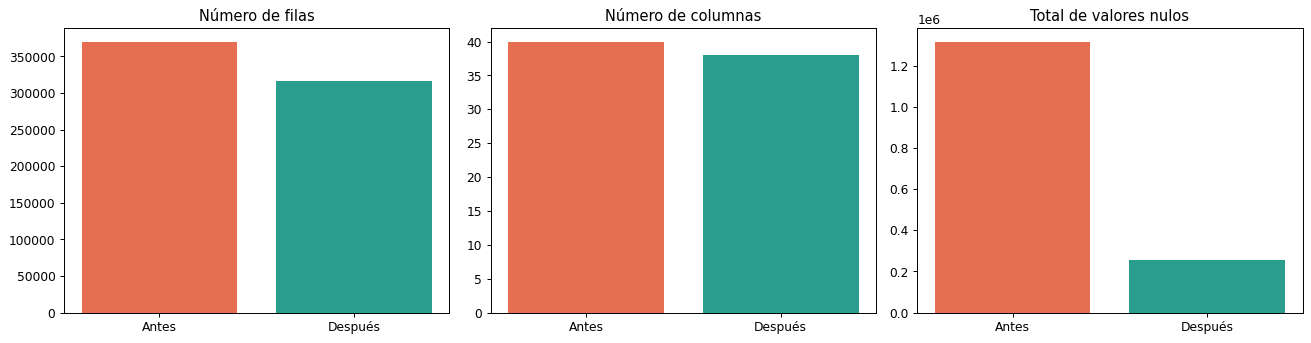

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(['Antes', 'Después'], [df_original.shape[0], df_confirmados.shape[0]], color=['#e76f51', '#2a9d8f'])
axes[0].set_title('Número de filas')

axes[1].bar(['Antes', 'Después'], [df_original.shape[1], df_confirmados.shape[1]], color=['#e76f51', '#2a9d8f'])
axes[1].set_title('Número de columnas')

axes[2].bar(['Antes', 'Después'], [df_original.isna().sum().sum(), df_confirmados.isna().sum().sum()],
            color=['#e76f51', '#2a9d8f'])
axes[2].set_title('Total de valores nulos')

plt.tight_layout()
plt.show()

**Sobre la variable objetivo:** no hay un "antes" de `Recuperada` porque es una variable que creamos nosotros, no estaba en el dataset original. Su distribucion "despues" ya se mostro en la seccion 13 (mas o menos 97,6% recuperada contra 2,3% no recuperada, sobre los 316.602 casos confirmados).

**Sobre la reduccion de filas:** que se pase de 370.332 a 316.602 filas no es porque limpiamos errores, es porque sacamos a proposito los casos sin resultado (pendientes y anulados), que se guardan aparte en `df_sin_resultado` para usarlos despues.

## 20. Control de calidad final

Para cerrar la etapa de limpieza, verificamos con codigo todos los puntos clave que debe cumplir el dataset antes de pasar a la etapa de modelado.

In [50]:
df_confirmados.info()

<class 'pandas.core.frame.DataFrame'>
Index: 316602 entries, 0 to 370331
Data columns (total 38 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   Factura                          316602 non-null  object        
 1   Fecha Factura                    316602 non-null  datetime64[ns]
 2   Ingreso                          316602 non-null  int64         
 3   Observacion Recepecion General   315405 non-null  string        
 4   Fecha de la Objecion             316602 non-null  datetime64[ns]
 5   Fecha Actualiza Saldo            316602 non-null  datetime64[ns]
 6   Codigo Conceptos Objecion        316602 non-null  string        
 7   Concepto de Objecion             316602 non-null  string        
 8   Observaciones por Item           225840 non-null  string        
 9   Hoja de Trabajo                  310451 non-null  float64       
 10  Codigo Servicio                  316602 non-null 

In [51]:
print("=== 1. Dimensiones ===")
print(f"df_confirmados: {df_confirmados.shape[0]:,} filas x {df_confirmados.shape[1]} columnas")

print()
print("=== 2. Tipos de datos ===")
print(df_confirmados.dtypes.value_counts())

print()
print("=== 3. Valores nulos ===")
nulos = df_confirmados.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(f"Columnas con al menos un nulo: {len(nulos)}")
print(nulos)

print()
print("=== 4. Duplicados exactos ===")
print(f"Filas duplicadas en df_confirmados: {df_confirmados.duplicated().sum()}")
print("(Los 9 pares de la sección 11 se conservan intencionalmente, no son un error de esta verificación)")

print()
print("=== 5. Artefacto '_x000D_' ===")
cols_texto_check = ['Observacion Recepecion General', 'Observaciones por Item',
                     'OBSERVACION TRAMITE GENERAL', 'Observaciones Trámite']
restantes = sum(df_confirmados[c].astype(str).str.contains('_x000D_', na=False).sum() for c in cols_texto_check)
print(f"Ocurrencias restantes de '_x000D_': {restantes}")

print()
print("=== 6. Inconsistencias categóricas (mayúsculas/espacios) ===")
for c in ['Especialidad', 'Regimen', 'Servicio', 'Entidad']:
    s = df_confirmados[c].dropna().astype(str)
    diff = s.nunique() - s.str.strip().str.upper().nunique()
    print(f"  {c}: diferencia entre categorías crudas y normalizadas = {diff}")

print()
print("=== 7. Fechas ===")
for c in ['Fecha Factura', 'Fecha de la Objecion', 'Fecha Actualiza Saldo', 'Fecha solicitud']:
    print(f"  {c}: tipo={df_confirmados[c].dtype}, nulos={df_confirmados[c].isna().sum()}")

print()
print("=== 8. Valores monetarios negativos ===")
cols_monet_check = ['Valor Unitario Procedimiento', 'Valor TotServicio PROCEDIMIENTO',
                     'Valor Entidad PROCEDIMIENTO', 'Valor Paciente PROCEDIMIENTO',
                     'Valor Objeción', 'Valor Aceptado', 'Abonado', 'Saldo']
for c in cols_monet_check:
    neg = (df_confirmados[c] < 0).sum()
    if neg > 0:
        print(f"  {c}: {neg} valores negativos (documentado en sección 16.3, no se corrige)")

print()
print("=== 9. Distribución del target ===")
print(df_confirmados['Recuperada'].value_counts(dropna=False))
print((df_confirmados['Recuperada'].value_counts(normalize=True, dropna=False) * 100).round(2))

print()
print("=== 10. Columnas personales eliminadas ===")
personales = ['Paciente', 'Medico', 'Facturador']
print(f"  {personales} -> presentes en df_confirmados: {[c for c in personales if c in df_confirmados.columns]}")
print(f"  (lista vacía = correctamente eliminadas)")

print()
print("=== 11. Columnas eliminadas por falta de utilidad ===")
sin_utilidad = ['Column1', 'Column2', 'Numero Radicación Trámite']
print(f"  {sin_utilidad} -> presentes en df_confirmados: {[c for c in sin_utilidad if c in df_confirmados.columns]}")
print(f"  (lista vacía = correctamente eliminadas)")

print()
print("=== 12. Variables excluidas por leakage ===")
print(f"  {variables_leakage}")
print(f"  -> ¿alguna está en X? {[v for v in variables_leakage if v in X.columns]}")
print(f"  (lista vacía = ninguna se filtró a X)")

print()
print("=== 13. Variables finales de X ===")
print(f"  {list(X.columns)} ({X.shape[1]} variables)")

print()
print("=== 14. Variable y ===")
print(f"  y = 'Recuperada', {y.shape[0]:,} valores, {y.isna().sum()} nulos, clases: {sorted(y.unique())}")

=== 1. Dimensiones ===
df_confirmados: 316,602 filas x 38 columnas

=== 2. Tipos de datos ===
string[python]    11
object            10
float64           10
datetime64[ns]     4
int32              2
int64              1
Name: count, dtype: int64

=== 3. Valores nulos ===
Columnas con al menos un nulo: 12
Codigo Suministro                  117067
Observaciones por Item              90762
Hoja de Trabajo                      6151
Valor Unitario Procedimiento         6151
Código Centro Costo Solicita         6151
Valor TotServicio PROCEDIMIENTO      6151
Valor Entidad PROCEDIMIENTO          6151
Valor Paciente PROCEDIMIENTO         6151
Fecha solicitud                      6151
Observaciones Trámite                2635
Observacion Recepecion General       1197
OBSERVACION TRAMITE GENERAL           344
dtype: int64

=== 4. Duplicados exactos ===
Filas duplicadas en df_confirmados: 9
(Los 9 pares de la sección 11 se conservan intencionalmente, no son un error de esta verificación)

=== 5. A

**Lo que muestra el control de calidad:** el dataset final no tiene duplicados por error (los 9 pares que si hay estan documentados y se dejaron a proposito), no quedan artefactos de exportacion, las categorias de texto estan normalizadas, las fechas quedaron bien tipificadas, los valores negativos que hay estan documentados y no parecen errores, la variable objetivo esta completa y su desbalance esta anotado, y `X`/`y` quedan libres de fuga de informacion y de columnas con datos personales.

## 21. Resumen de decisiones

| Decisión | Acción realizada | Motivo |
|---|---|---|
| Columnas constantes/vacías (`Column1`, `Column2`, `Numero Radicación Trámite`) | Eliminadas (sección 6) | No aportan información |
| Información personal (`Paciente`, `Medico`, `Facturador`) | Eliminada (sección 7) | Privacidad y sin valor predictivo |
| Nombres de columnas | Sin cambios | No se encontraron problemas de formato reales |
| Artefactos `_x000D_` y saltos de línea en observaciones | Limpiados | Dejan el texto legible, evitan ruido |
| Espacios sobrantes (`Entidad`, `Codigo Conceptos Objecion`) | Eliminados (`strip`) | Evitan que el mismo valor se trate como distinto |
| Categorías duplicadas por escritura (`Servicio`) | Normalizadas a mayúsculas/espacios simples | Unifican categorías equivalentes |
| Nulos estructurales en columnas de ítem (`Servicio`, `Especialidad`, `Centro de Costo`, `Codigo Servicio`) | Reemplazados por categoría explícita (`"SIN INFORMACION"` / `"SIN CODIGO"`) | El nulo tiene un significado de negocio real, no es un dato faltante por error |
| Nulos en columnas numéricas de ítem (`Valor Unitario/TotServicio/Entidad/Paciente PROCEDIMIENTO`) | Se conservan sin imputar | Imputar inventaría un valor que no existe para esas objeciones globales |
| 9 pares de filas 100% idénticas (sección 11) | **Analizadas y conservadas**, no se eliminan | No hay evidencia suficiente de que sean errores administrativos; podrían ser insumos genuinamente repetidos dentro de la misma factura |
| Facturas que se repiten con distintos ítems | **No** se tratan como duplicados | Corresponden a ítems/servicios distintos de la misma factura |
| `Fecha Factura` | Convertida a `datetime` | Permite cálculos temporales |
| Variables derivadas de fecha (`Anio/Mes/Dia Semana Objecion`) | Creadas | Útiles para el análisis de tendencias mostrado en el proyecto |
| Valores atípicos en `Valor Objeción` | Conservados, no eliminados | Corresponden a procedimientos de alta complejidad, no a errores |
| Variable objetivo `Recuperada` | Creada a partir de `Valor Aceptado` (0 → Recuperada, >0 → No recuperada) | Regla de negocio acordada con el hospital; el reporte no trae un resultado explícito |
| Estados `Pendiente` y `Anulado` | Excluidos del conjunto de entrenamiento (conservados aparte) | No tienen un resultado definitivo todavía |
| `Abonado` negativo | Conservado, no corregido | Corresponde a un posible ajuste contable válido, no a un error evidente |
| `Abonado`/`Saldo`/`Fecha Actualiza Saldo`/`Estado`/`Concepto`/`Cod Concepto`/`Etiqueta Objeción`/`Observaciones Trámite` | Conservadas en el dataset, **excluidas de X** por fuga de información (sección 17) | Contienen o reflejan directamente el resultado del trámite |
| Desbalance de clases en `Recuperada` | Documentado, no corregido | El balanceo corresponde a la etapa de modelado |

## 22. Conclusiones

**¿Que problemas de calidad tenia el dataset al principio?** El reporte que nos dieron tenia columnas vacias o constantes, informacion personal identificable, fechas almacenadas en formatos diferentes, artefactos de exportacion en el texto, categorias duplicadas por como estaban escritas, y bastantes nulos que en su mayoria tenian un significado de negocio (objeciones sin item especifico, o sin resultado todavia), no eran errores al azar.

**¿Cuales fueron los problemas mas importantes?** Diriamos que tres cosas pesaron mas que el resto: (1) no habia una variable objetivo explicita, tuvimos que armarla nosotros a partir de `Valor Aceptado`; (2) habia 53.046 registros sin resultado definitivo (`Pendiente`) mas 684 `Anulado`, que si se hubieran metido por error al entrenamiento habrian dañado el modelo con una etiqueta que no existe; y (3) la fuga de informacion, varias columnas (`Concepto`, `Cod Concepto`, `Observaciones Trámite`, entre otras) describen directa o indirectamente como termino el tramite y tuvimos que sacarlas de las variables predictoras.

**¿Que tecnicas de limpieza usamos?** Quitamos columnas sin informacion y con datos personales, normalizamos texto (espacios, mayusculas, artefactos de exportacion), convertimos bien los tipos de dato, tratamos los nulos segun lo que significaban (categoria explicita o dejarlos ahi a proposito), analizamos los duplicados exactos sin eliminarlos de una, excluimos con documentacion los registros sin resultado conocido, e hicimos un analisis explicito de fuga de informacion antes de decidir las variables predictoras.

**¿Cuantos registros y columnas quedaron?** El dataset final de modelado (`df_confirmados`) tiene 316.602 filas y 38 columnas (se eliminaron 6 columnas del original: 3 vacias/constantes y 3 de informacion personal, y se agregaron 4 columnas nuevas: `Anio Objecion`, `Mes Objecion`, `Dia Semana Objecion` y `Recuperada`). De esas 38 columnas, 14 quedan como predictoras en `X`, el resto se conserva por trazabilidad pero no se usa para entrenar el modelo.

**¿Por que el dataset final sirve mas para mineria de datos?** Porque ahora tiene tipos de dato correctos, categorias consistentes, no tiene informacion personal, tiene una variable objetivo clara, solo incluye los registros que si tienen resultado conocido, y a diferencia de una version anterior de este mismo notebook, el conjunto `X` esta explicitamente libre de fuga de informacion, comprobado por codigo y no solo porque lo dijimos.

**¿Que falta revisar en la etapa de analisis exploratorio/modelamiento?**
- El desbalance de clases (~97,6% / ~2,3%) va a necesitar una estrategia aparte (sobremuestreo, submuestreo, ajustar pesos, o usar metricas como F1/recall en vez de accuracy). A proposito no aplicamos ninguna tecnica de balanceo en esta etapa de limpieza.
- Los 9 pares de filas idénticas de la seccion 11 se dejaron ahi, valdria la pena volver a mirarlos si en el modelado se ve que estan afectando mucho algun resultado.
- Las 51 entidades (EPS/aseguradoras) con menos de 10 registros tal vez habria que agruparlas en una categoria "Otras" para que no queden categorias tan dispersas en el modelo.
- Los campos de texto libre (`Observaciones por Item`, `Observacion Recepecion General`, `OBSERVACION TRAMITE GENERAL`) quedaron fuera de `X` en esta version, pero podrian servir si se procesan con NLP mas adelante.
- Tambien valdria la pena mirar si el tiempo entre `Fecha Factura` y `Fecha de la Objecion` (que ya se puede calcular porque las fechas quedaron bien tipificadas) tiene algo que ver con el resultado de la glosa.

El dataset no quedo perfecto, todavia tiene nulos a proposito, texto libre sin estructurar y variables con distinta granularidad, pero si quedo bastante mas confiable, consistente, trazable y sin fuga de informacion conocida que el archivo original que nos dio el hospital.

## 23. Exportación del dataset limpio

In [52]:
import os, json as _json
os.makedirs(RAIZ / 'data/procesados', exist_ok=True)

df_confirmados.to_csv(
    RAIZ / "data/procesados/dataset_glosas_limpio.csv",
    index=False,
    encoding="utf-8-sig"
)

df_sin_resultado.to_csv(
    RAIZ / "data/procesados/dataset_glosas_sin_resultado.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardamos también la lista de variables predictoras usada en X, para trazabilidad
with open(RAIZ / "data/procesados/variables_predictoras_X.json", "w", encoding="utf-8") as f:
    _json.dump(variables_predictoras, f, ensure_ascii=False, indent=2)

print("Dataset final de modelado (confirmados):", df_confirmados.shape)
print("Dataset de casos sin resultado (para trazabilidad):", df_sin_resultado.shape)
print("Variables predictoras (X) guardadas:", len(variables_predictoras))

Dataset final de modelado (confirmados): (316602, 38)
Dataset de casos sin resultado (para trazabilidad): (53730, 38)
Variables predictoras (X) guardadas: 14
